In [1]:
# # NetfluxZeiglerFibroblastODE_run.py 
# # Automatically generated by Netflux on 23-Oct-2022 


# import numpy as np 
# from scipy.integrate import ode 
# import matplotlib.pyplot as plt 
# import itertools
# import pandas as pd
# import seaborn as sns


# import NetfluxODE_5
# import NetfluxODE_5_params
#  # 
# [speciesNames, tau, ymax, y0, w, n, EC50] = NetfluxODE_5_params.loadParams()

# from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector

#  # 
# [speciesNames, tau, ymax, y0, w, n, EC50] = NetfluxODE_5_params.loadParams()

# # Read the CSV file
# loss_log_df = pd.read_csv("loss_log_DOF_cluster.csv")
# # Find the row with the smallest value in the last column
# min_loss_row = loss_log_df.loc[loss_log_df.iloc[:, -1].idxmin()]
# # Extract the vector using all columns from the first to the penultimate column
# # vector = min_loss_row.iloc[:-1].values
# vector = np.array([1.01915194, 1.09999999, 0.94966909, 1.1, 0.62873844])
# print(vector)
# # Convert the vector to a numpy array
# w_vec = build_weight_vector(vector, family_id_vector)

# # bas=0.1
# bas=0.1
# y0=bas*np.ones(len(y0))
# # print('y0',y0)


# EC50v = 0.568305675
# nv    = 1.301942649
# bv    = 0.291697537
# pv    = 0.507453875

# # EC50=(EC50/0.6)*(0.55)  #some
# EC50=EC50v*np.ones(len(EC50))  #all
# # print('EC50',EC50)

# # n=(n/1.4)*(1.5)
# n=nv*np.ones(len(n)) #all
# print('n',n)



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import ode

In [3]:

from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector

import NetfluxODE_5
import NetfluxODE_5_sensitivity
import NetfluxODE_5_params
 # 
[speciesNames, tau, ymax, y0r, wr, nr, EC50r] = NetfluxODE_5_params.loadParams()

# Read the CSV file
loss_log_df = pd.read_csv("loss_log_DOF_cluster.csv")
# Find the row with the smallest value in the last column
min_loss_row = loss_log_df.loc[loss_log_df.iloc[:, -1].idxmin()]
# Extract the vector using all columns from the first to the penultimate column
# vector = min_loss_row.iloc[:-1].values
vector = np.array([1.01915194, 1.09999999, 0.94966909, 1.1, 0.62873844])
print(vector)
# Convert the vector to a numpy array
w_vec = build_weight_vector(vector, family_id_vector)

# bas=0.1
bas=0.1
y0=bas*np.ones(len(y0r))
# print('y0',y0)

EC50v = 0.587798419904243
nv    = 1.39569768592174
bv    = 0.283201091629315
pv    = 0.653814229335876

# EC50v = 0.568305675 ##same as "...._perTheta.py"
# nv    = 1.301942649
# bv    = 0.291697537
# pv    = 0.507453875

# EC50=(EC50/0.6)*(0.55)  #some
EC50=EC50v*np.ones(len(EC50r))  #all
# print('EC50',EC50)

# n=(n/1.4)*(1.5)
n=nv*np.ones(len(nr)) #all

[1.01915194 1.09999999 0.94966909 1.1        0.62873844]


In [4]:
AngII = 0 
AT1R = 1 
AGT = 2 
ACE = 3 
NOX = 4 
ROS = 5 
ET1 = 6 
ETAR = 7 
DAG = 8 
PKC = 9 
AC = 10 
cAMP = 11 
PKA = 12 
CREB = 13 
CBP = 14 
TGFB = 15 
TGFB1R = 16 
smad3 = 17 
smad7 = 18 
latentTGFB = 19 
PDGF = 20 
PDGFR = 21 
cGMP = 22 
PKG = 23 
mechanical = 24 
B1int = 25 
Rho = 26 
ROCK = 27 
Ca = 28 
IL6 = 29 
gp130 = 30 
STAT = 31 
IL1 = 32 
IL1RI = 33 
TNFa = 34 
TNFaR = 35 
NFKB = 36 
PI3K = 37 
Akt = 38 
p38 = 39 
TRAF = 40 
ASK1 = 41 
MKK3 = 42 
PP1 = 43 
JNK = 44 
abl = 45 
Rac1 = 46 
MEKK1 = 47 
MKK4 = 48 
ERK = 49 
Ras = 50 
Raf = 51 
MEK1 = 52 
FAK = 53 
epac = 54 
Factin = 55 
FA = 56 
migration = 57 
cmyc = 58 
CTGF = 59 
proliferation = 60 
SRF = 61 
aSMA = 62 
AP1 = 63 
TIMP1 = 64 
TIMP2 = 65 
PAI1 = 66 
proMMP14 = 67 
proMMP1 = 68 
proMMP2 = 69 
proMMP9 = 70 
MMP1 = 71 
MMP2 = 72 
MMP9 = 73 
MMP14 = 74 
fibronectin = 75 
periostin = 76 
CImRNA = 77 
CIIImRNA = 78 
CI = 79 
CIII = 80 
FGF = 81 
FGFR1 = 82 
Shp2 = 83 
FRS2 = 84 
Src = 85 
cortactin = 86 
Grb2Sos = 87 
NWASP = 88 
Arp23 = 89 
TEAD = 90 
YAP = 91 
LATS12 = 92 
piezo1 = 93 
infusionTGFB=94
infusionFGF=95

biochinputs = [mechanical, FGF, IL6, IL1, TNFa, PDGF, infusionTGFB, AngII, ET1]
for idx in biochinputs:
    y0[idx] = bv

In [5]:

tspan = [0, 100] 
t = [] 
dt = tspan[1]/200. 
r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False) 
r.set_initial_value(y0,tspan[0]).set_f_params(tau,ymax,w_vec,n,EC50) 
results = np.empty([0,len(speciesNames)]) 
while r.successful() and r.t <= tspan[1]: 
	r.integrate(r.t + dt) 
	results = np.append(results,[r.y],axis=0) 
	t.append(r.t) 


# print(r.t)

# fig, ax = plt.subplots() 
# ax.plot(t[:],results[:,proliferation], label='proliferation') #proliferation
# ax.plot(t[:],results[:,CI], label='CI', linewidth=3) #CI
# ax.plot(t[:],results[:,CIII], label='CIII') #CII
# 	# ax.plot(t[:],results[:,i]) #CII
# 	# if results[-1,i]>0.4:
# 	# 	print(i)
# # ax.plot(tt[:],resultss[:,27])#NP
# # ax.plot(tt[:],resultss[:,11])#NE

# ax.set(xlabel='Time',ylabel='Fractional activation') 
# ax.legend()

# print(y0)


In [6]:
# plt.plot(t[:],results[:,Shp2], label='CIII') #CII

In [7]:
# # y0=0.15*np.ones((100,))
# # print(np.shape(y0))
# # print(y0)

# b=np.linspace(0.25,1,30)
# CIr = np.zeros(len(b))
# CIIIr = np.zeros(len(b))
# CImRNAr = np.zeros(len(b))
# CIIImRNAr = np.zeros(len(b))
# proliferationr = np.zeros(len(b))
# TIMP1r=np.zeros(len(b))
# TIMP2r=np.zeros(len(b))
# MMP2r=np.zeros(len(b))
# MMP9r=np.zeros(len(b))
# MMP1r=np.zeros(len(b))
# MMP14r=np.zeros(len(b))
# Factinr=np.zeros(len(b))
# aSMAr=np.zeros(len(b))
# migrationr=np.zeros(len(b))
# proMMP14r = np.zeros(len(b))
# proMMP1r = np.zeros(len(b))
# proMMP2r = np.zeros(len(b))
# proMMP9r = np.zeros(len(b))
# FAKr = np.zeros(len(b))
# # FA


# c=0

# p=0.3
# # y0[19]=p
# # y0[PDGF]=p
# # y0[IL1]=p
# # y0[IL6]=p

# print(y0)



In [8]:
# for i in b:
#     y0[mechanical]=i  #mechanical
#     tspan = [0, 60] 
#     t = [] 
#     dt = tspan[1]/150. 
#     r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False) 
#     r.set_initial_value(y0,tspan[0]).set_f_params(tau,ymax,w_vec,n,EC50) 
#     results = np.empty([0,len(speciesNames)]) 
#     while r.successful() and r.t <= tspan[1]: 
#         r.integrate(r.t + dt) 
#         results = np.append(results,[r.y],axis=0) 
#         t.append(r.t) 
#     #Get results
#     CIr[c] = results[-1, CI]  # CI
#     CIIIr[c] = results[-1, CIII]  # CIII
#     CImRNAr[c] = results[-1, CImRNA]  # CImRNA
#     CIIImRNAr[c] = results[-1, CIIImRNA]  # CIIImRNA
#     proliferationr[c] = results[-1, proliferation]  # proliferation
#     TIMP1r[c] = results[-1, TIMP1]  # TIMP1
#     TIMP2r[c] = results[-1, TIMP2]  # TIMP2
#     MMP2r[c] = results[-1, MMP2]  # MMP2
#     MMP9r[c] = results[-1, MMP9]  # MMP9
#     MMP1r[c] = results[-1, MMP1]  # MMP1
#     MMP14r[c] = results[-1, MMP14]  # MMP14
#     Factinr[c] = results[-1, Factin]  # Factin
#     migrationr[c] = results[-1, migration]  # migration
#     aSMAr[c] = results[-1, aSMA]  # aSMA
#     proMMP14r[c] = results[-1, proMMP14]  # proMMP14
#     proMMP1r[c] = results[-1, proMMP1]  # proMMP1
#     proMMP2r[c] = results[-1, proMMP2]  # proMMP2
#     proMMP9r[c] = results[-1, proMMP9]  # proMMP9
#     FAKr[c] = results[-1, FAK]  # FAK
#     c+=1

In [9]:
# plt.rcParams["figure.figsize"] = (20, 15)

# fig, axes = plt.subplots(4, 5)

# # First subplot: Combine CI and CIII
# axes[0, 0].plot(b, CIr, '-', color='blue', label='CI')
# axes[0, 0].plot(b, CIIIr, '--', color='blue', label='CIII')
# axes[0, 0].set_title('CI and CIII')
# axes[0, 0].set_xlabel('Mechanical Stimuli fractional activation')
# axes[0, 0].set_ylabel('Steady state fractional Activation')
# axes[0, 0].legend()

# # Second subplot: MMP2
# axes[0, 1].plot(b, MMP2r, '-', color='blue', label='MMP2')
# axes[0, 1].set_title('MMP2')
# axes[0, 1].set_xlabel('Mechanical Stimuli fractional activation')
# axes[0, 1].set_ylabel('Steady state fractional Activation')
# axes[0, 1].legend()

# # Third subplot: MMP9
# axes[0, 2].plot(b, MMP9r, '--', color='blue', label='MMP9')
# axes[0, 2].set_title('MMP9')
# axes[0, 2].set_xlabel('Mechanical Stimuli fractional activation')
# axes[0, 2].set_ylabel('Steady state fractional Activation')
# axes[0, 2].legend()

# # Fourth subplot: MMP1
# axes[0, 3].plot(b, MMP1r, '-', color='green', label='MMP1')
# axes[0, 3].set_title('MMP1')
# axes[0, 3].set_xlabel('Mechanical Stimuli fractional activation')
# axes[0, 3].set_ylabel('Steady state fractional Activation')
# axes[0, 3].legend()

# # Fifth subplot: MMP14
# axes[0, 4].plot(b, MMP14r, '--', color='green', label='MMP14')
# axes[0, 4].set_title('MMP14')
# axes[0, 4].set_xlabel('Mechanical Stimuli fractional activation')
# axes[0, 4].set_ylabel('Steady state fractional Activation')
# axes[0, 4].legend()

# # Sixth subplot: proMMP2
# axes[1, 0].plot(b, proMMP2r, '-', color='blue', label='proMMP2')
# axes[1, 0].set_title('proMMP2')
# axes[1, 0].set_xlabel('Mechanical Stimuli fractional activation')
# axes[1, 0].set_ylabel('Steady state fractional Activation')
# axes[1, 0].legend()

# # Seventh subplot: proMMP9
# axes[1, 1].plot(b, proMMP9r, '--', color='blue', label='proMMP9')
# axes[1, 1].set_title('proMMP9')
# axes[1, 1].set_xlabel('Mechanical Stimuli fractional activation')
# axes[1, 1].set_ylabel('Steady state fractional Activation')
# axes[1, 1].legend()

# # Eighth subplot: proMMP1
# axes[1, 2].plot(b, proMMP1r, '-', color='green', label='proMMP1')
# axes[1, 2].set_title('proMMP1')
# axes[1, 2].set_xlabel('Mechanical Stimuli fractional activation')
# axes[1, 2].set_ylabel('Steady state fractional Activation')
# axes[1, 2].legend()

# # Ninth subplot: proMMP14
# axes[1, 3].plot(b, proMMP14r, '--', color='green', label='proMMP14')
# axes[1, 3].set_title('proMMP14')
# axes[1, 3].set_xlabel('Mechanical Stimuli fractional activation')
# axes[1, 3].set_ylabel('Steady state fractional Activation')
# axes[1, 3].legend()

# # Tenth subplot: TIMP1
# axes[1, 4].plot(b, TIMP1r, '-', color='blue', label='TIMP1')
# axes[1, 4].set_title('TIMP1')
# axes[1, 4].set_xlabel('Mechanical Stimuli fractional activation')
# axes[1, 4].set_ylabel('Steady state fractional Activation')
# axes[1, 4].legend()

# # Eleventh subplot: TIMP2
# axes[2, 0].plot(b, TIMP2r, '--', color='blue', label='TIMP2')
# axes[2, 0].set_title('TIMP2')
# axes[2, 0].set_xlabel('Mechanical Stimuli fractional activation')
# axes[2, 0].set_ylabel('Steady state fractional Activation')
# axes[2, 0].legend()

# # Twelfth subplot: Proliferation
# axes[2, 1].plot(b, proliferationr, ':', color='0.5', label='Proliferation')
# axes[2, 1].set_title('Proliferation')
# axes[2, 1].set_xlabel('Mechanical Stimuli fractional activation')
# axes[2, 1].set_ylabel('Steady state fractional Activation')
# axes[2, 1].legend()

# # Thirteenth subplot: aSMAr
# axes[2, 2].plot(b, aSMAr, '-', color='blue', label='aSMAr')
# axes[2, 2].set_title('aSMAr')
# axes[2, 2].set_xlabel('Mechanical Stimuli fractional activation')
# axes[2, 2].set_ylabel('Steady state fractional Activation')
# axes[2, 2].legend()

# # Fourteenth subplot: migrationr
# axes[2, 3].plot(b, migrationr, '--', color='blue', label='migrationr')
# axes[2, 3].set_title('migrationr')
# axes[2, 3].set_xlabel('Mechanical Stimuli fractional activation')
# axes[2, 3].set_ylabel('Steady state fractional Activation')
# axes[2, 3].legend()

# # Fifteenth subplot: Factinr
# axes[2, 4].plot(b, Factinr, '-', color='green', label='Factinr')
# axes[2, 4].set_title('Factinr')
# axes[2, 4].set_xlabel('Mechanical Stimuli fractional activation')
# axes[2, 4].set_ylabel('Steady state fractional Activation')
# axes[2, 4].legend()

# # Sixteenth subplot: FAKr
# axes[3, 0].plot(b, FAKr, '--', color='green', label='FAKr')
# axes[3, 0].set_title('FAKr')
# axes[3, 0].set_xlabel('Mechanical Stimuli fractional activation')
# axes[3, 0].set_ylabel('Steady state fractional Activation')
# axes[3, 0].legend()

# # Seventeenth subplot: Combine CImRNA and CIIImRNA
# axes[3, 1].plot(b, CImRNAr, '-', color='blue', label='CImRNA')
# axes[3, 1].plot(b, CIIImRNAr, '--', color='blue', label='CIIImRNA')
# axes[3, 1].set_title('CImRNA and CIIImRNA')
# axes[3, 1].set_xlabel('Mechanical Stimuli fractional activation')
# axes[3, 1].set_ylabel('Steady state fractional Activation')
# axes[3, 1].legend()

# # Adjust layout for better spacing
# plt.tight_layout()
# plt.show()


In [10]:
b1=np.linspace(0,1,30)
b2=np.linspace(bv,bv+pv,30)
# biochinputs = [FGF, IL6, IL1, TNFa, PDGF, infusionTGFB, AngII, ET1]
biochinputs = [infusionTGFB]
# biochinputsn = ["FGF", "IL6", "IL1", "TNFa", "PDGF", "infusionTGFB", "AngII", "ET1"]  # Names for labeling
biochinputsn = ["infusionTGFB"]  # Names for labeling


In [11]:
# Initialize the matrix to store steady states
# Dimensions: [number of species, number of biochemical inputs, number of tension levels]
steady_states = np.zeros((len(speciesNames), len(biochinputs), len(b2), len(b1)))

tspan = [0, 60] 
dt = tspan[1] / 6000. 

for tension_idx, tension in enumerate(b1):
    y0[mechanical] = tension  # Set mechanical tension
    for bioch_idx, bioch in enumerate(biochinputs):
        for perturbation_idx, perturbation in enumerate(b2):
            y0[bioch] = perturbation  # Set biochemical input perturbation
            r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=1e-8, atol=1e-10, with_jacobian=False) 
            r.set_initial_value(y0, tspan[0]).set_f_params(tau, ymax, w_vec, n, EC50) 
            results = np.empty([0, len(speciesNames)]) 
            t = []  # Reset time array
            while r.successful() and r.t <= tspan[1]: 
                r.integrate(r.t + dt) 
                results = np.append(results, [r.y], axis=0) 
                t.append(r.t) 
            
            # Correct: Store steady-state values FOR THIS perturbation
            steady_states[:, bioch_idx, perturbation_idx, tension_idx] = results[-1, :]
            
            # Reset the biochemical input to its baseline value
            y0[bioch] = bv



In [12]:
# # import matplotlib.pyplot as plt
# # import numpy as np
# # import matplotlib.pyplot as plt
# import matplotlib.cm as cm
# import matplotlib.colors as mcolors

# # Setup
# node_of_interest = 'MMP1'  # <-- Change to whatever species you want
# node_idx = speciesNames.index(node_of_interest)

# biochinputsn = ["FGF", "IL6", "IL1", "TNFa", "PDGF", "infusionTGFB", "AngII", "ET1"]  # Names for labeling
# # Make sure this list matches the biochinputs order

# # Create a colormap for tension values
# norm = mcolors.Normalize(vmin=min(b1), vmax=max(b1))
# cmap = cm.viridis

# # Create figure with 2 rows and 4 columns
# fig, axs = plt.subplots(2, 4, figsize=(20, 8), sharey=True)

# # Flatten the axes array for easier iteration
# axs = axs.flatten()

# for ax, bioch_name in zip(axs, biochinputsn):
#     bioch_idx = biochinputsn.index(bioch_name)
    
#     # Plot each tension curve
#     for tension_idx, tension in enumerate(b1):
#         color = cmap(norm(tension))
        
#         # Plot steady-state activation vs biochemical input perturbation
#         ax.plot(b2, steady_states[node_idx, bioch_idx, :, tension_idx], color=color)

#     ax.set_title(f'{bioch_name}')
#     ax.set_xlabel(f'{bioch_name} Dose')
#     ax.grid(True)

# # Set common ylabel
# axs[0].set_ylabel(f'{node_of_interest} Normalized Activation')
# # Set y limits # leave as it is for aSMA, CI, CIII, YAP
# # axs[0].set_ylim(0.718, 0.724) #MMP2
# # axs[0].set_ylim(0.99, 1) # proliferation
# axs[0].set_ylim(0.99, 1.01) #proMMP9
# # axs[0].set_ylim(0.5, 0.51) #TIMP1

# # Add colorbars
# for ax in axs:
#     sm = cm.ScalarMappable(cmap=cmap, norm=norm)
#     sm.set_array([])
#     cbar = plt.colorbar(sm, ax=ax)
#     cbar.set_label('Tension')

# fig.tight_layout()
# #save figure:
# plt.savefig('aSMA_tension_biochinputs.png', dpi=300)
# plt.show()



In [13]:
# # List of species to plot
# species_to_plot = ['TIMP1', 'MMP1', 'MMP2', 'CImRNA', 'CI', 'proliferation', 'aSMA', 'fibronectin', 'YAP']

# # Get indices of the species
# species_indices = [speciesNames.index(species) for species in species_to_plot]

# # Setup
# # biochinputsn = ["FGF", "IL6", "IL1", "TNFa", "PDGF", "infusionTGFB", "AngII", "ET1"]  # Names for labeling
# tgfb_idx = biochinputsn.index("infusionTGFB")  # Index for TGF-β infusion

# # Create a colormap for tension values
# norm = mcolors.Normalize(vmin=min(b1), vmax=max(b1))
# cmap = cm.viridis

# # Create figure with 3 rows and 3 columns
# fig, axs = plt.subplots(3, 3, figsize=(20, 15), sharey=True)

# # Flatten the axes array for easier iteration
# axs = axs.flatten()

# for ax, species, species_idx in zip(axs, species_to_plot, species_indices):
#     # Plot each tension curve
#     for tension_idx, tension in enumerate(b1):
#         color = cmap(norm(tension))
        
#         # Plot steady-state activation vs TGF-β infusion perturbation
#         ax.plot(b2, steady_states[species_idx, tgfb_idx, :, tension_idx], color=color)

#     ax.set_title(f'{species}')
#     ax.set_xlabel('TGF-β Dose')
#     ax.grid(True)

# # Set common ylabel
# axs[0].set_ylabel('Normalized Activation')

# # Add colorbars
# for ax in axs:
#     sm = cm.ScalarMappable(cmap=cmap, norm=norm)
#     sm.set_array([])
#     cbar = plt.colorbar(sm, ax=ax)
#     cbar.set_label('Tension')

# fig.tight_layout()
# # Save figure
# plt.savefig('tgfb_tension_species_activation.png', dpi=300)
# plt.show()

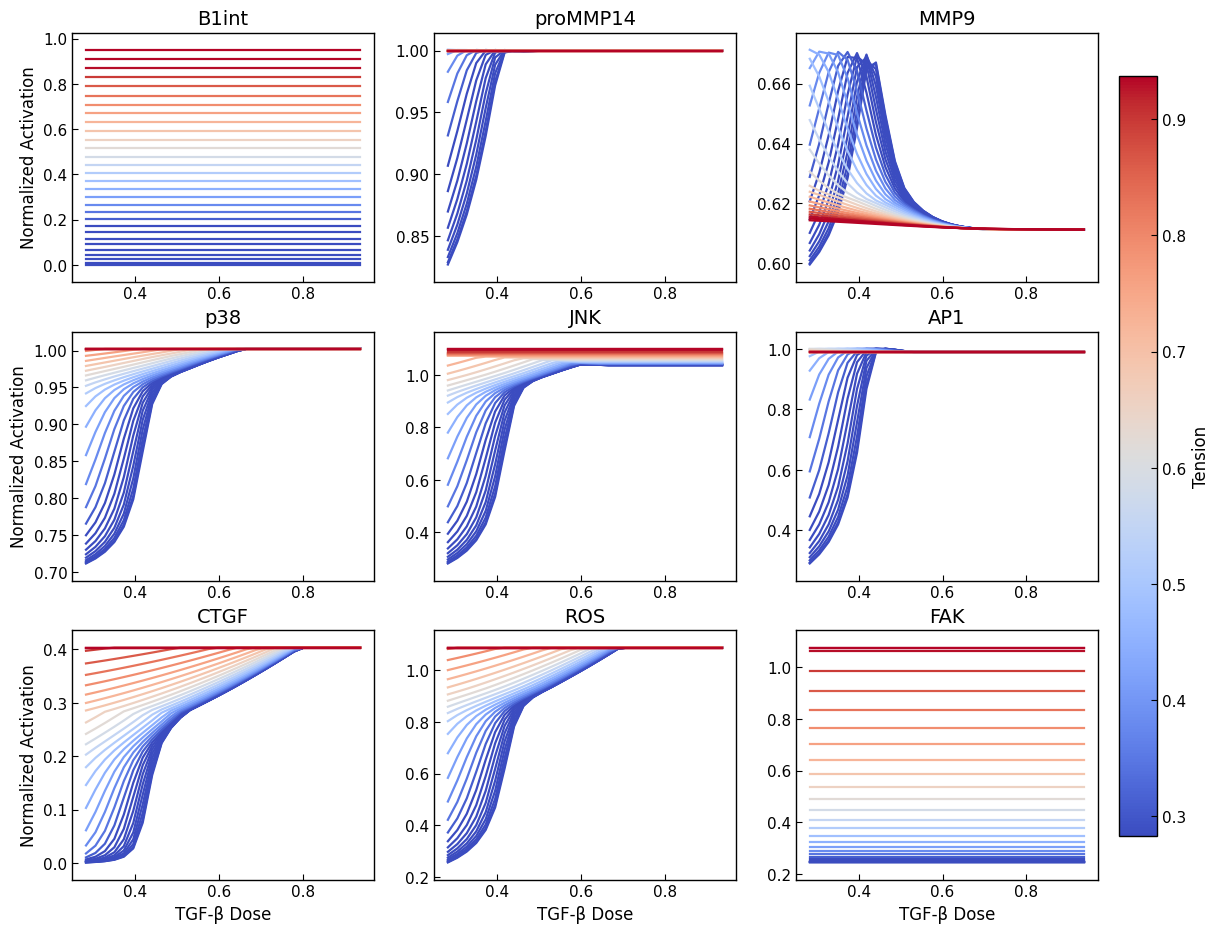

Saved: tgfb_tension_species_activation_paper_c.png


In [14]:
# --- Pretty, paper-ready TGFB × Tension plots ------------------------------
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ---------------- Aesthetics (fonts, ticks, spines) ------------------------
mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,        # display dpi; savefig dpi set below
})

# --- Inputs you already have ------------------------------------------------
# species_to_plot = ['TIMP1', 'MMP1', 'MMP2', 'CImRNA', 'CI',
                #    'proliferation', 'aSMA', 'fibronectin', 'YAP']
species_to_plot = ['B1int', 'proMMP14', 'MMP9', 'p38', 'JNK', 'AP1',
                   'CTGF', 'ROS',  'FAK']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Colormap for tension
norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
# cmap = cm.viridis
cmap = cm.coolwarm

# --- Figure layout ----------------------------------------------------------
nrows, ncols = 3, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 11))  # slightly more compact
axs = axs.ravel()

# We'll gather the “global” min/max just in case you want to standardize later
global_min, global_max = np.inf, -np.inf

for ax, spec_name, spec_idx in zip(axs, species_to_plot, species_indices):
    # Plot all tension curves for this species
    ymins, ymaxs = [], []
    for t in b1:
        y = steady_states[spec_idx, tgfb_idx, :, list(b1).index(t)]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    # Title
    ax.set_title(spec_name)

    # Clean style: no grid, light spines
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    # Comfortable limits focused on relevant range per subplot
    if ymins and ymaxs:
        ymin = np.min(ymins)
        ymax = np.max(ymaxs)
        # Protect against zero range
        yr = max(ymax - ymin, 1e-3)
        pad = 0.08 * yr
        ax.set_ylim(ymin - pad, ymax + pad)
        global_min = min(global_min, ymin)
        global_max = max(global_max, ymax)

# Axis labels only on outer edges for a clean grid
for i, ax in enumerate(axs):
    # Left column y-labels
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    # Bottom row x-labels
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')
##redefine range in y axis for specific plots if desired
# axs[0].set_ylim(0.495, 0.5025) #TIMP1
# axs[1].set_ylim(1.0, 1.0020) #MMP1
# axs[2].set_ylim(0.718, 0.727) #MMP2
# axs[6].set_ylim(0.99, 1.01) #proliferation
# axs[3].set_ylim(0.99, 1.015) #fibronectin
# axs[6].set_ylim(0.99, 1.01) #aSMA
# axs[8].set_ylim(0.99, 1.01) #YAP
# axs[4].set_ylim(0.99, 1.01) #CI
# axs[3].set_ylim(0.99, 1.01) #CImRNA
# --- Single shared colorbar on the right -----------------------------------
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# Attach to all axes so it occupies the right gutter once
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

# fig.tight_layout()

# --- Save (300 dpi as requested) -------------------------------------------
out_path = 'tgfb_tension_species_activation_paper_c.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")


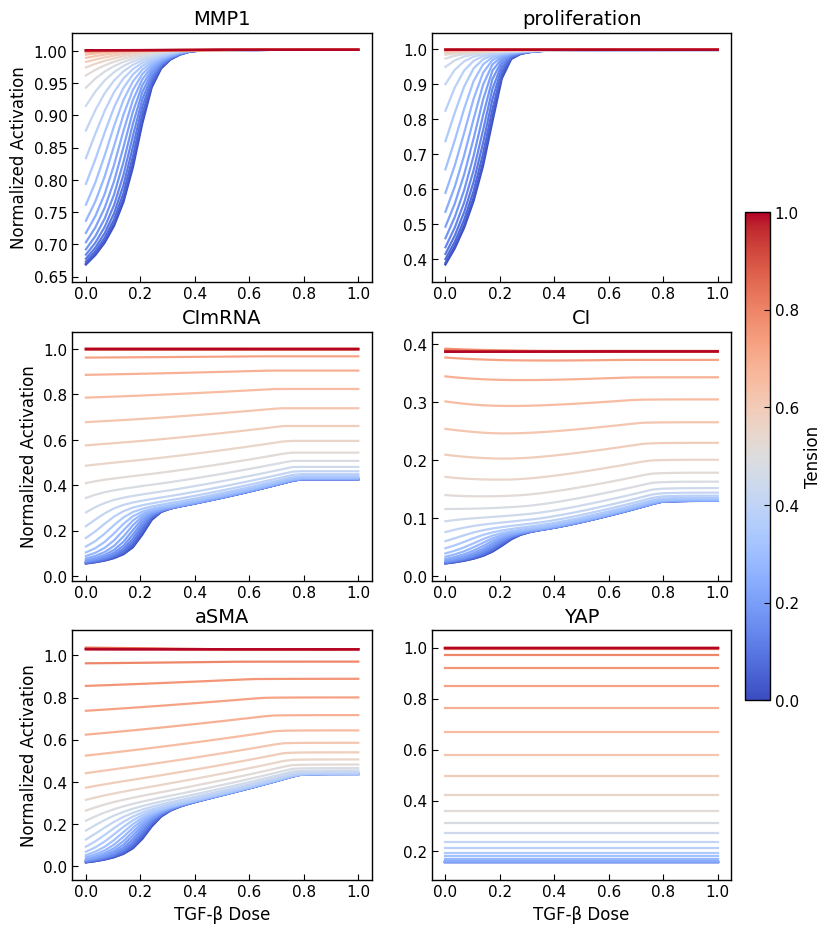

Saved: tgfb_tension_species_activation_paper_23.png


In [15]:
# --- Pretty, paper-ready TGFB × Tension plots ------------------------------
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ---------------- Aesthetics (fonts, ticks, spines) ------------------------
mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,        # display dpi; savefig dpi set below
})

# --- Inputs you already have ------------------------------------------------
# species_to_plot = ['TIMP1', 'MMP1', 'MMP2', 'CImRNA', 'CI',
                #    'proliferation', 'aSMA', 'fibronectin', 'YAP']
species_to_plot = ['MMP1', 'proliferation', 'CImRNA', 'CI',
                    'aSMA',  'YAP']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Colormap for tension
norm = mcolors.Normalize(vmin=float(np.min(b1)), vmax=float(np.max(b1)))
# cmap = cm.viridis
cmap = cm.coolwarm

# --- Figure layout ----------------------------------------------------------
nrows, ncols = 3, 2
fig, axs = plt.subplots(nrows, ncols, figsize=(9, 11))  # slightly more compact
axs = axs.ravel()

# We'll gather the “global” min/max just in case you want to standardize later
global_min, global_max = np.inf, -np.inf

for ax, spec_name, spec_idx in zip(axs, species_to_plot, species_indices):
    # Plot all tension curves for this species
    ymins, ymaxs = [], []
    for t in b1:
        y = steady_states[spec_idx, tgfb_idx, :, list(b1).index(t)]
        ax.plot(b1, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    # Title
    ax.set_title(spec_name)

    # Clean style: no grid, light spines
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    # Comfortable limits focused on relevant range per subplot
    if ymins and ymaxs:
        ymin = np.min(ymins)
        ymax = np.max(ymaxs)
        # Protect against zero range
        yr = max(ymax - ymin, 1e-3)
        pad = 0.08 * yr
        ax.set_ylim(ymin - pad, ymax + pad)
        global_min = min(global_min, ymin)
        global_max = max(global_max, ymax)

# Axis labels only on outer edges for a clean grid
for i, ax in enumerate(axs):
    # Left column y-labels
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    # Bottom row x-labels
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')
##redefine range in y axis for specific plots if desired
# axs[0].set_ylim(0.48, 0.513) #TIMP1
# axs[0].set_ylim(1.0, 1.0020) #MMP1
# axs[1].set_ylim(0.99, 1.015) #fibronectin
# axs[2].set_ylim(0.718, 0.727) #MMP2
# axs[6].set_ylim(0.99, 1.01) #proliferation
# axs[6].set_ylim(0.99, 1.01) #aSMA
# axs[8].set_ylim(0.99, 1.01) #YAP
# axs[4].set_ylim(0.99, 1.01) #CI
# axs[3].set_ylim(0.99, 1.01) #CImRNA

# --- Single shared colorbar on the right -----------------------------------
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# Attach to all axes so it occupies the right gutter once
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

# fig.tight_layout()

# --- Save (300 dpi as requested) -------------------------------------------
out_path = 'tgfb_tension_species_activation_paper_23.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")




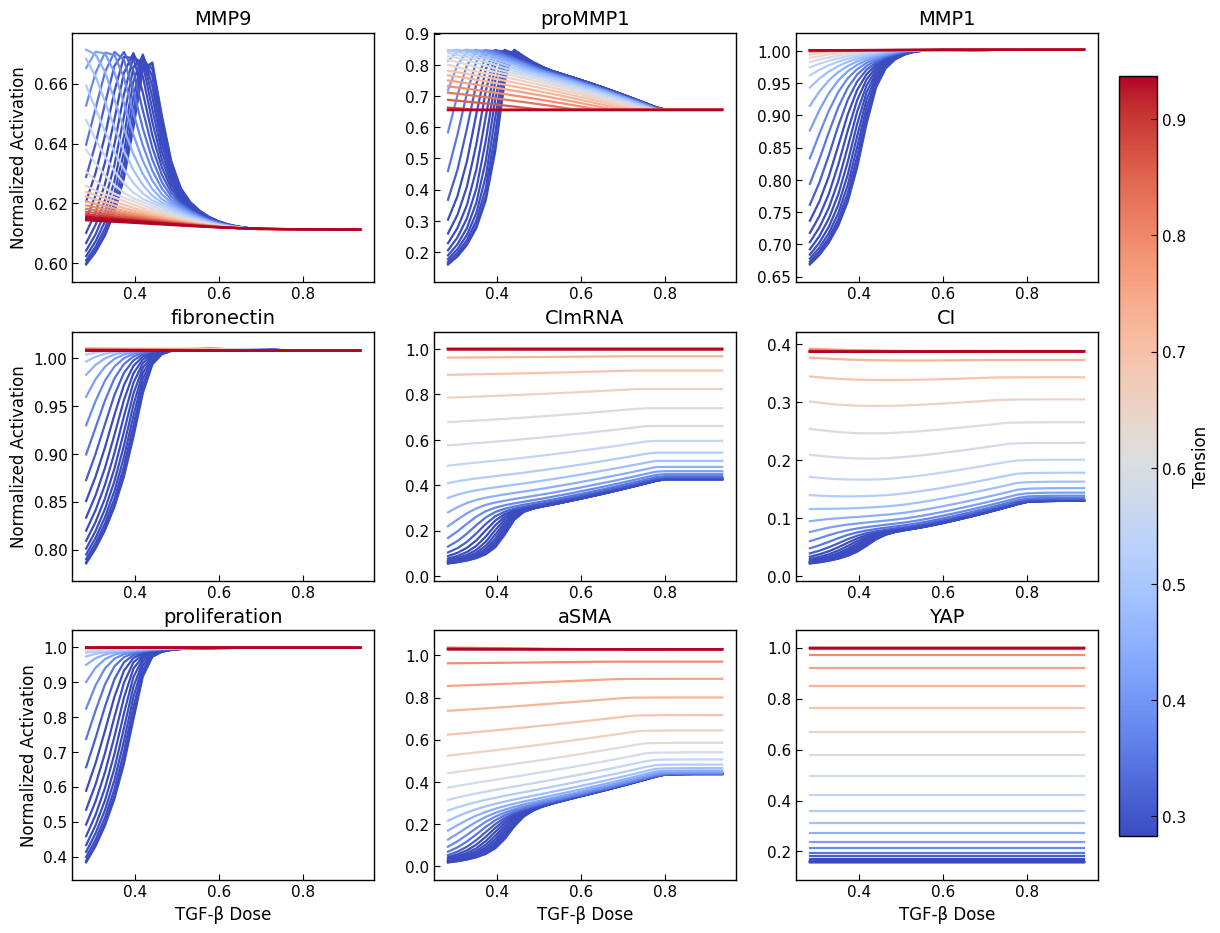

Saved: tgfb_tension_species_activation_paper_c.png


In [16]:
# --- Paper-ready TGF-β x Tension plots with zoom insets -------------------
# Same 3x3 layout as the base figure, all panels span the full y-range.
# The first three panels (TIMP1, MMP1, MMP2) carry a zoomed inset showing
# the near-plateau region for closer inspection of fine structure.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,
})

species_to_plot = ['MMP9', 'proMMP1', 'MMP1', 'fibronectin', 'CImRNA', 'CI',
                   'proliferation', 'aSMA', 'YAP']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Zoom y-limits for the first three panels only.
zoom_ylims = {
    0: (0.495, 0.504),   # TIMP1
    1: (1.0000, 1.0020),  # MMP1
    # 2: (0.718, 0.727),    # MMP2
    3: (1.0, 1.013),     # fibronectin
    6: (0.99, 1.0),      # proliferation
}

norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
cmap = cm.coolwarm

nrows, ncols = 3, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 11))
axs = axs.ravel()

for i, (ax, spec_name, spec_idx) in enumerate(zip(axs, species_to_plot, species_indices)):
    ymins, ymaxs = [], []
    for k, t in enumerate(b1):
        y = steady_states[spec_idx, tgfb_idx, :, k]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    ax.set_title(spec_name)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    if ymins and ymaxs:
        ymin, ymax = np.min(ymins), np.max(ymaxs)
        pad = 0.08 * max(ymax - ymin, 1e-3)
        ax.set_ylim(ymin - pad, ymax + pad)

    # Zoom inset (only first three panels).
    # if i in zoom_ylims:
    #     axin = ax.inset_axes([0.42, 0.10, 0.55, 0.42])
    #     for k, t in enumerate(b1):
    #         y = steady_states[spec_idx, tgfb_idx, :, k]
    #         axin.plot(b2, y, color=cmap(norm(t)), lw=1.2)
    #     axin.set_xlim(float(np.min(b2)), float(np.max(b2)))
    #     axin.set_ylim(*zoom_ylims[i])
    #     axin.tick_params(labelsize=8, length=2)
    #     axin.set_facecolor('white')
    #     for spine in axin.spines.values():
    #         spine.set_linewidth(0.8)

for i, ax in enumerate(axs):
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')

# # Add vertical lines in the first row subfigures
# for i in range(3):  # First row corresponds to indices 0, 1, 2
#     axs[i].axvline(x=0.43, color='0.5', linestyle='--', linewidth=0.8)  # Adjust x as needed

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

# out_path = 'tgfb_tension_species_activation_paper_c_with_insets.png'
out_path = 'tgfb_tension_species_activation_paper_c.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")

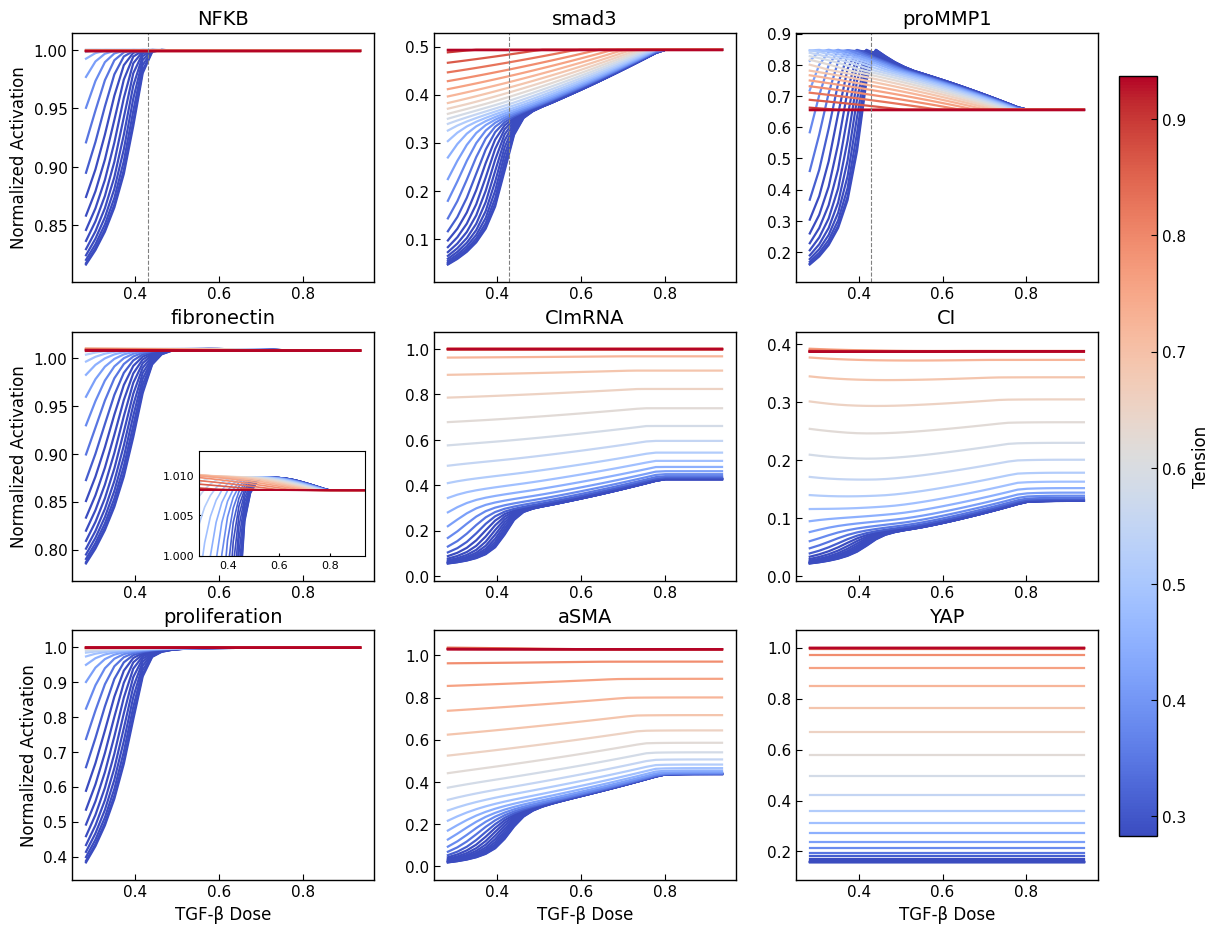

Saved: tgfb_tension_species_activation_paper_c_with_insets2.png


In [17]:
# --- Paper-ready TGF-β x Tension plots with zoom insets -------------------
# Same 3x3 layout as the base figure, all panels span the full y-range.
# The first three panels (TIMP1, MMP1, MMP2) carry a zoomed inset showing
# the near-plateau region for closer inspection of fine structure.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,
})

species_to_plot = ['NFKB', 'smad3', 'proMMP1', 'fibronectin', 'CImRNA', 'CI',
                   'proliferation', 'aSMA', 'YAP']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Zoom y-limits for the first three panels only.
zoom_ylims = {
    # 0: (0.495, 0.504),   # TIMP1
    # 1: (1.0000, 1.0020),  # MMP1
    # 2: (0.718, 0.727),    # MMP2
    3: (1.0, 1.013),     # fibronectin
}

norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
cmap = cm.coolwarm

nrows, ncols = 3, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 11))
axs = axs.ravel()

for i, (ax, spec_name, spec_idx) in enumerate(zip(axs, species_to_plot, species_indices)):
    ymins, ymaxs = [], []
    for k, t in enumerate(b1):
        y = steady_states[spec_idx, tgfb_idx, :, k]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    ax.set_title(spec_name)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    if ymins and ymaxs:
        ymin, ymax = np.min(ymins), np.max(ymaxs)
        pad = 0.08 * max(ymax - ymin, 1e-3)
        ax.set_ylim(ymin - pad, ymax + pad)

    # Zoom inset (only first three panels).
    if i in zoom_ylims:
        axin = ax.inset_axes([0.42, 0.10, 0.55, 0.42])
        for k, t in enumerate(b1):
            y = steady_states[spec_idx, tgfb_idx, :, k]
            axin.plot(b2, y, color=cmap(norm(t)), lw=1.2)
        axin.set_xlim(float(np.min(b2)), float(np.max(b2)))
        axin.set_ylim(*zoom_ylims[i])
        axin.tick_params(labelsize=8, length=2)
        axin.set_facecolor('white')
        for spine in axin.spines.values():
            spine.set_linewidth(0.8)

for i, ax in enumerate(axs):
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')

# Add vertical lines in the first row subfigures
for i in range(3):  # First row corresponds to indices 0, 1, 2
    axs[i].axvline(x=0.43, color='0.5', linestyle='--', linewidth=0.8)  # Adjust x as needed

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

out_path = 'tgfb_tension_species_activation_paper_c_with_insets2.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")

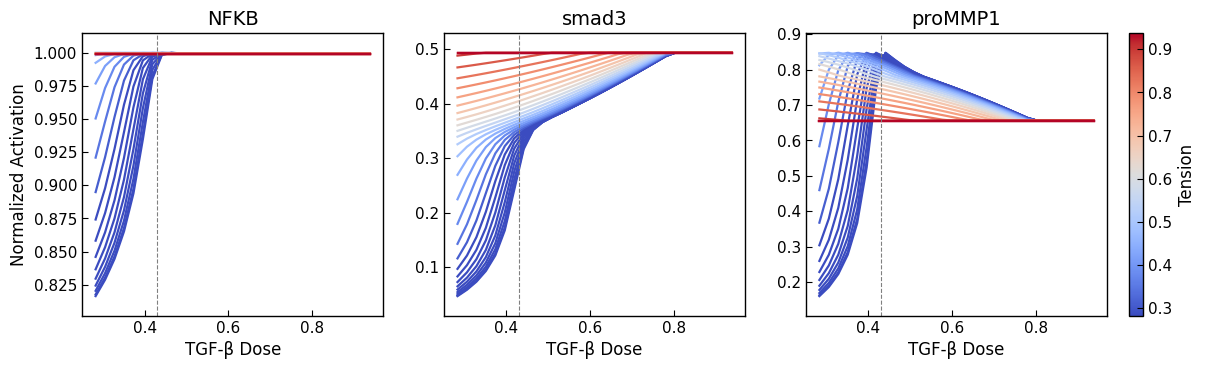

Saved: suppl3.png


In [18]:
# --- Paper-ready TGF-β x Tension plots with zoom insets -------------------
# Same 3x3 layout as the base figure, all panels span the full y-range.
# The first three panels (TIMP1, MMP1, MMP2) carry a zoomed inset showing
# the near-plateau region for closer inspection of fine structure.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,
})

species_to_plot = ['NFKB', 'smad3', 'proMMP1']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Zoom y-limits for the first three panels only.
zoom_ylims = {
    # 0: (0.495, 0.504),   # TIMP1
    # 1: (1.0000, 1.0020),  # MMP1
    # 2: (0.718, 0.727),    # MMP2
    3: (1.0, 1.013),     # fibronectin
}

norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
cmap = cm.coolwarm

nrows, ncols = 1, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 3.667))
axs = axs.ravel()

for i, (ax, spec_name, spec_idx) in enumerate(zip(axs, species_to_plot, species_indices)):
    ymins, ymaxs = [], []
    for k, t in enumerate(b1):
        y = steady_states[spec_idx, tgfb_idx, :, k]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    ax.set_title(spec_name)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    if ymins and ymaxs:
        ymin, ymax = np.min(ymins), np.max(ymaxs)
        pad = 0.08 * max(ymax - ymin, 1e-3)
        ax.set_ylim(ymin - pad, ymax + pad)

    # Zoom inset (only first three panels).
    if i in zoom_ylims:
        axin = ax.inset_axes([0.42, 0.10, 0.55, 0.42])
        for k, t in enumerate(b1):
            y = steady_states[spec_idx, tgfb_idx, :, k]
            axin.plot(b2, y, color=cmap(norm(t)), lw=1.2)
        axin.set_xlim(float(np.min(b2)), float(np.max(b2)))
        axin.set_ylim(*zoom_ylims[i])
        axin.tick_params(labelsize=8, length=2)
        axin.set_facecolor('white')
        for spine in axin.spines.values():
            spine.set_linewidth(0.8)

for i, ax in enumerate(axs):
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')

# Add vertical lines in the first row subfigures
for i in range(3):  # First row corresponds to indices 0, 1, 2
    axs[i].axvline(x=0.43, color='0.5', linestyle='--', linewidth=0.8)  # Adjust x as needed

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

out_path = 'suppl3.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")

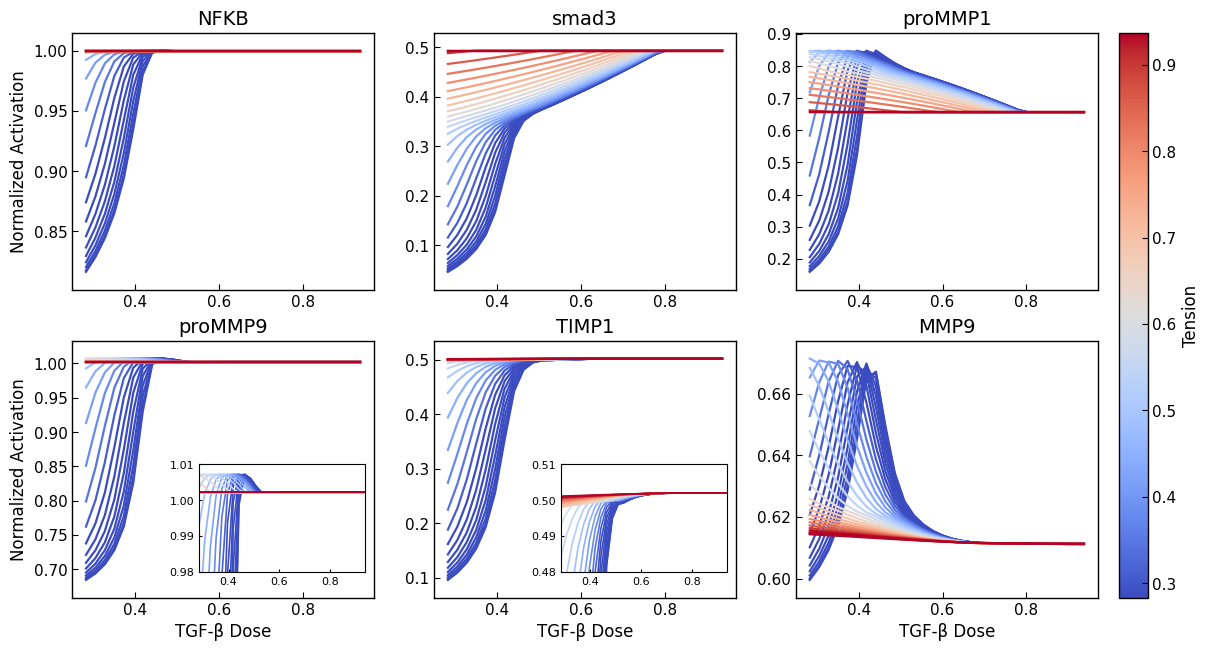

Saved: suppl3_2.png


In [19]:
# --- Paper-ready TGF-β x Tension plots with zoom insets -------------------
# Same 3x3 layout as the base figure, all panels span the full y-range.
# The first three panels (TIMP1, MMP1, MMP2) carry a zoomed inset showing
# the near-plateau region for closer inspection of fine structure.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors

mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,
})

species_to_plot = ['NFKB', 'smad3', 'proMMP1','proMMP9', 'TIMP1', 'MMP9']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

# Zoom y-limits for the first three panels only.
zoom_ylims = {
    3: (0.98, 1.01),   # proMMP9
    4: (0.48, 0.51),  # TIMP1
    # 2: (0.718, 0.727),    # MMP9

}

norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
cmap = cm.coolwarm

nrows, ncols = 2, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 7.334))
axs = axs.ravel()

for i, (ax, spec_name, spec_idx) in enumerate(zip(axs, species_to_plot, species_indices)):
    ymins, ymaxs = [], []
    for k, t in enumerate(b1):
        y = steady_states[spec_idx, tgfb_idx, :, k]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    ax.set_title(spec_name)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    if ymins and ymaxs:
        ymin, ymax = np.min(ymins), np.max(ymaxs)
        pad = 0.08 * max(ymax - ymin, 1e-3)
        ax.set_ylim(ymin - pad, ymax + pad)

    # Zoom inset (only first three panels).
    if i in zoom_ylims:
        axin = ax.inset_axes([0.42, 0.10, 0.55, 0.42])
        for k, t in enumerate(b1):
            y = steady_states[spec_idx, tgfb_idx, :, k]
            axin.plot(b2, y, color=cmap(norm(t)), lw=1.2)
            # axin.axvline(x=0.47, color='0.5', linestyle='--', linewidth=0.8)
        axin.set_xlim(float(np.min(b2)), float(np.max(b2)))
        axin.set_ylim(*zoom_ylims[i])
        axin.tick_params(labelsize=8, length=2)
        axin.set_facecolor('white')
        for spine in axin.spines.values():
            spine.set_linewidth(0.8)

for i, ax in enumerate(axs):
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')

# Add vertical lines in the first row subfigures
# for i in [3,4,5]:  # First row corresponds to indices 0, 1, 2
#     axs[i].axvline(x=0.47, color='0.5', linestyle='--', linewidth=0.8)  # Adjust x as needed

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

out_path = 'suppl3_2.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")